# API 2: Plotting

Initialize KAN and create dataset

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune
from xkan.symbolic import fix_symbolic, set_mode
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 3 grid intervals (grid=3).
model = KANNetwork([2,5,1], grid=3, k=3, seed=1, device=device)

# create dataset f(x,y) = exp(sin(pi*x)+y^2): training and test sets, inputs under 'x', labels under 'y'
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

cuda


(torch.Size([1000, 2]), torch.Size([1000, 1]))

Plot KAN at initialization

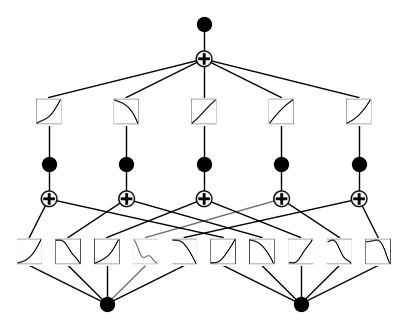

In [2]:
# plot KAN at initialization (the curves over the training inputs)
plot(model, train['x'], beta=100);

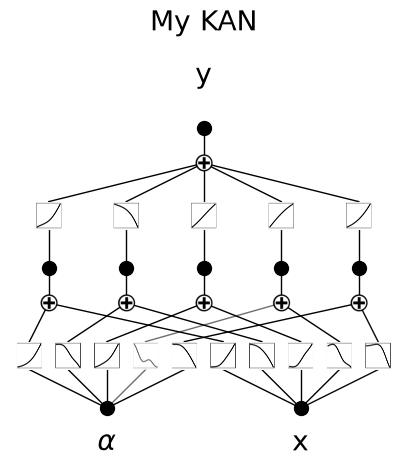

In [3]:
# if you want to add variable names and title
plot(model, train['x'], beta=100, in_vars=[r'$\alpha$', 'x'], out_vars=['y'], title = 'My KAN');

Train KAN with sparsity regularization

In [4]:
# train the model
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.051758365808084544 test RMSE 0.049793690982140586


$\beta$ controls the transparency of activations. Larger $\beta$ => more activation functions show up. We usually want to set a proper beta such that only important connections are visually significant. transparency is set to be ${\rm tanh}(\beta \phi)$ where $\phi$ is the scale of the activation function (metric='forward_u'), normalized scale (metric='forward_n') or the feature attribution score (metric='backward'). By default $\beta=3$ and metric='backward'.

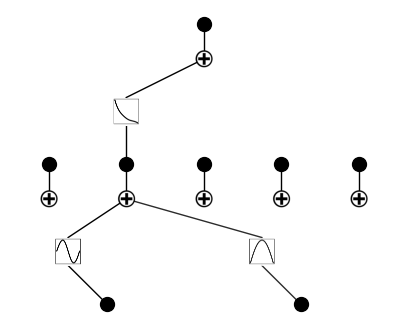

In [5]:
plot(model, train['x']);

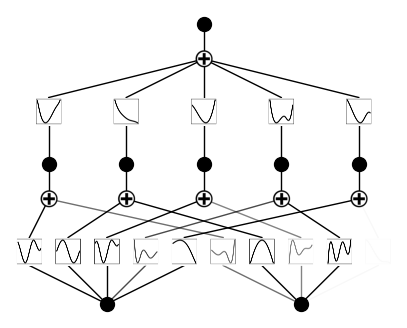

In [6]:
plot(model, train['x'], beta=100000);

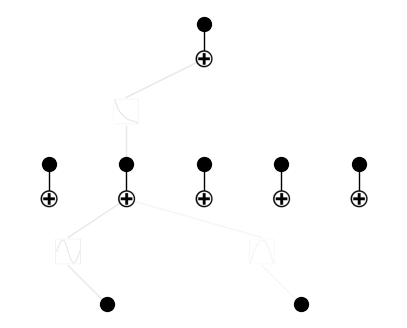

In [7]:
plot(model, train['x'], beta=0.1);

plotting with different metrics: 'forward_n', 'forward_u', 'backward'

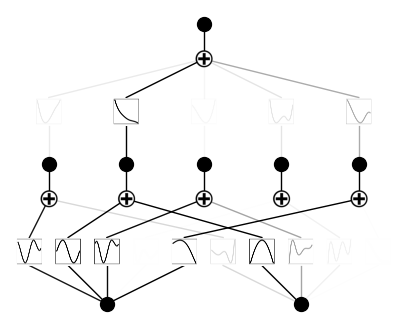

In [8]:
plot(model, train['x'], metric='forward_n', beta=100);

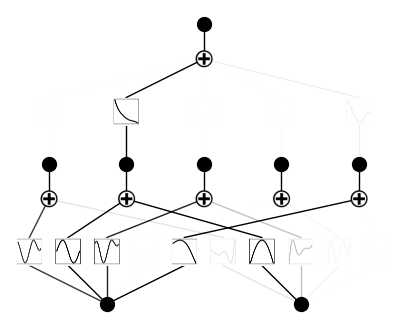

In [9]:
plot(model, train['x'], metric='forward_u', beta=100);

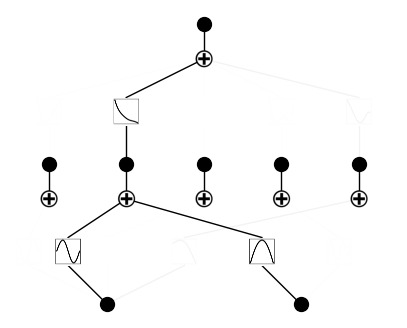

In [10]:
plot(model, train['x'], metric='backward', beta=100);

Remove insignificant neurons

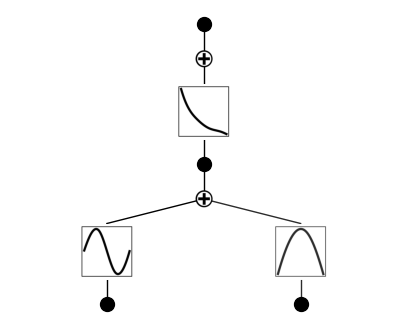

In [11]:
model = prune(model, train['x'])
plot(model, train['x']);

Resize the figure using the "scale" parameter. By default: 0.5

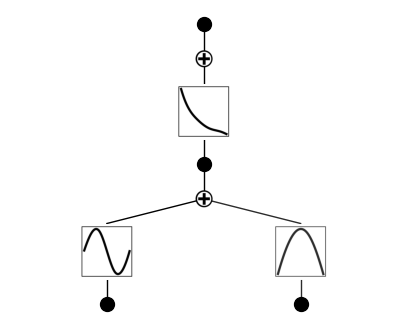

In [12]:
plot(model, train['x'], scale=0.5);

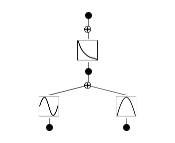

In [13]:
plot(model, train['x'], scale=0.2);

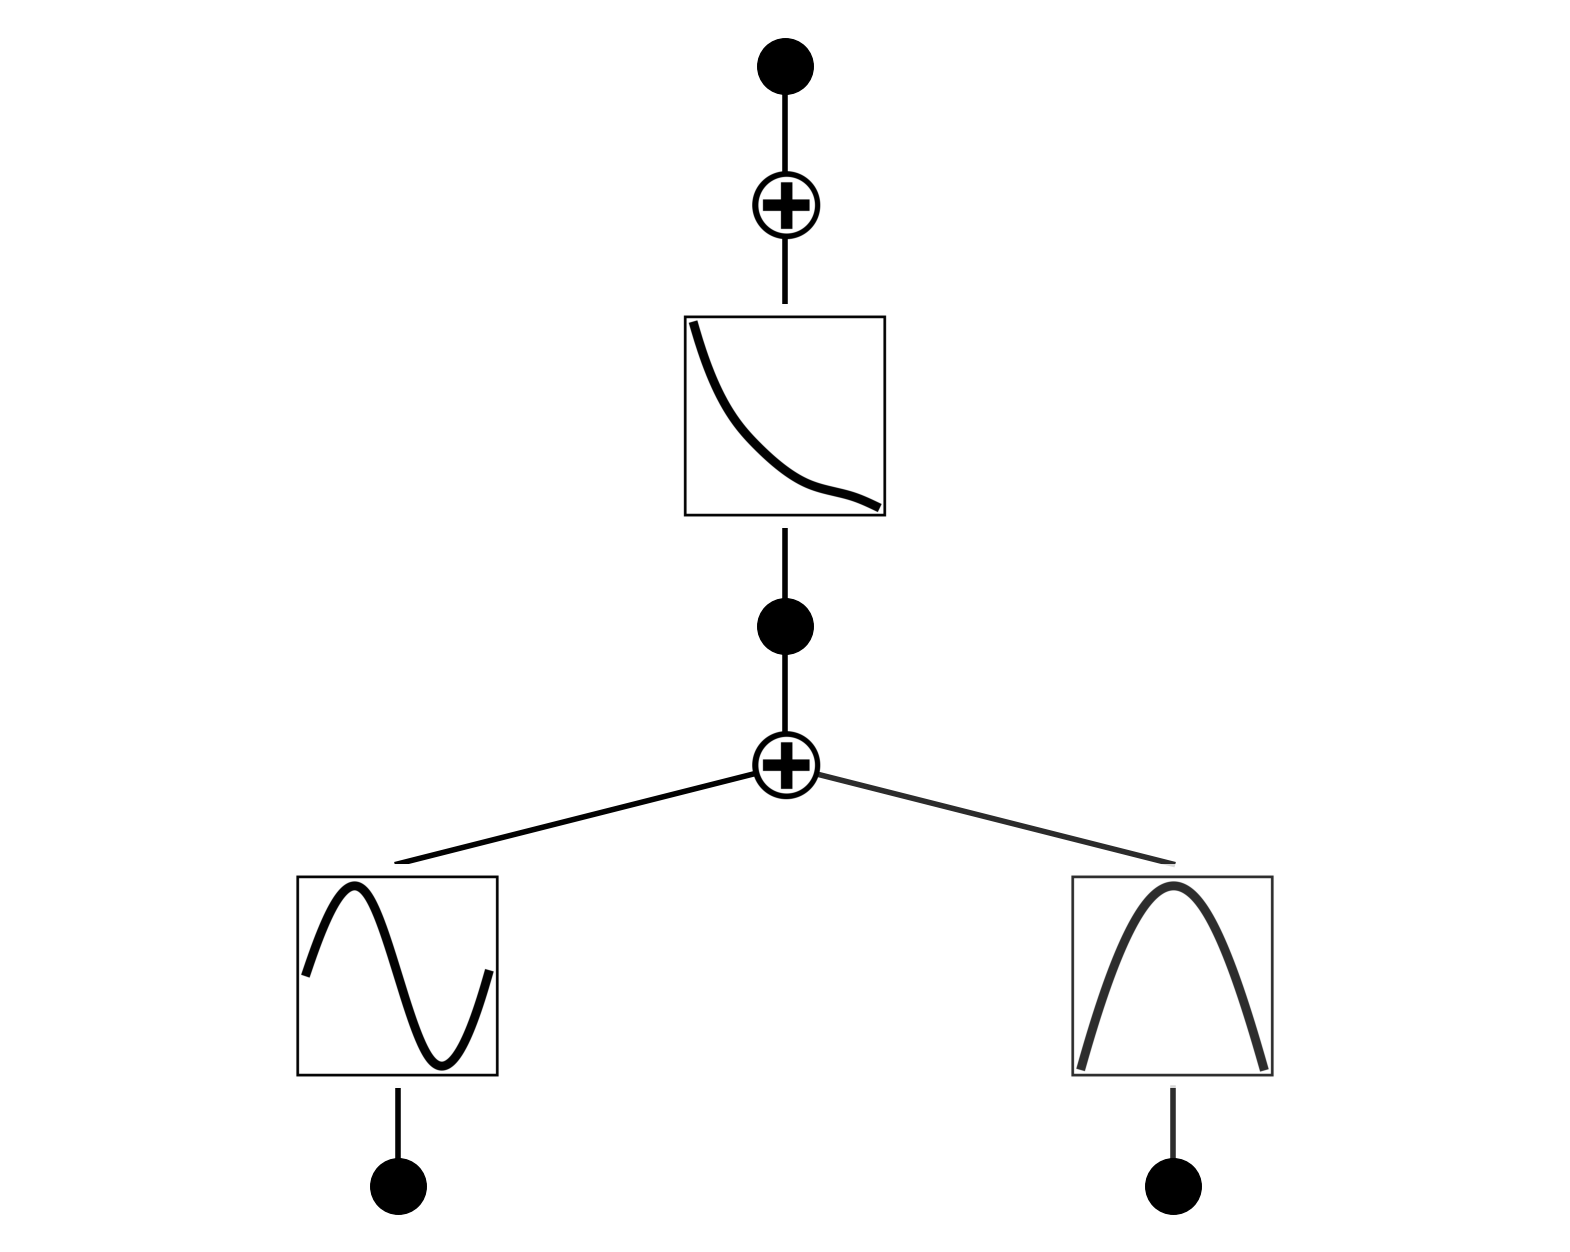

In [14]:
plot(model, train['x'], scale=2.0);

If you want to see sample distribution in addition to the line, set "sample=True"

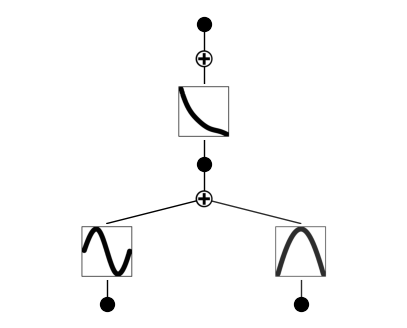

In [15]:
plot(model, train['x'], sample=True);

The samples are more visible if we use a smaller number of samples

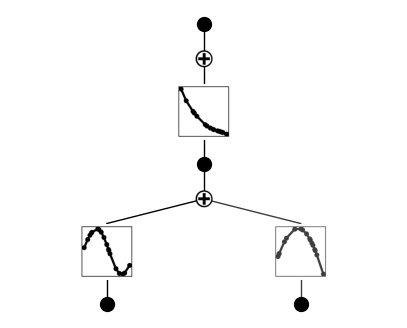

In [16]:
plot(model, train['x'][:20], sample=True);

If a function is set to be symbolic, it becomes red

In [17]:
fix_symbolic(model, 0, 1, 0, 'x^2', train['x'], verbose=True)

Best value at boundary.
r2 is 0.9989925622940063


tensor(0.9990, device='cuda:0')

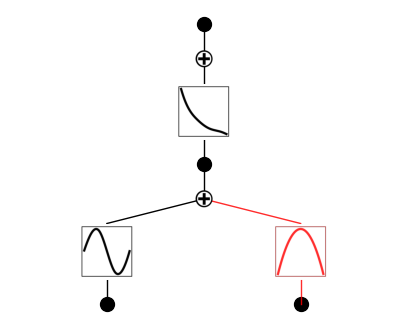

In [18]:
plot(model, train['x']);

If a function is set to be both symbolic and numeric (its output is the addition of symbolic and spline), then it shows up in purple

In [19]:
set_mode(model, 0, 1, 0, mode='ns')

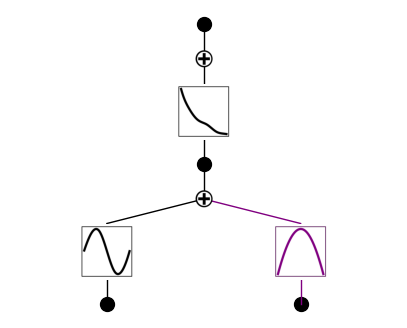

In [20]:
plot(model, train['x'], beta=100);